# CARGAR DATASET


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import zipfile
from pathlib import Path

print("OpenCV:", cv2.__version__)
print("Librerías cargadas correctamente")


OpenCV: 5.0.0
Librerías cargadas correctamente


In [2]:
from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [3]:
ruta_zip = "/content/drive/MyDrive/archive.zip"
dataset = zipfile.ZipFile(ruta_zip, "r")
archivos = [
    nombre for nombre in dataset.namelist()
    if nombre.lower().endswith(
        (".jpg", ".jpeg", ".png")
    )
]
print("Cantidad de imágenes:", len(archivos))
print("Primera imagen:", archivos[0])


Cantidad de imágenes: 15515
Primera imagen: garbage_classification/battery/battery1.jpg


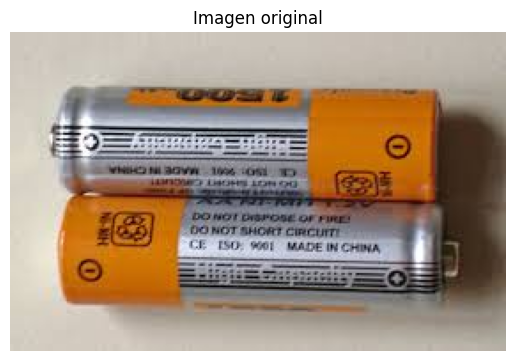

In [4]:
nombre = archivos[0]
datos = dataset.read(nombre)
matriz = np.frombuffer(datos, dtype=np.uint8)
imagen = cv2.imdecode(matriz, cv2.IMREAD_COLOR)
imagen_rgb = cv2.cvtColor(
    imagen, cv2.COLOR_BGR2RGB
)
plt.imshow(imagen_rgb)
plt.title("Imagen original")
plt.axis("off")
plt.show()


#ESCALA DE GRISES

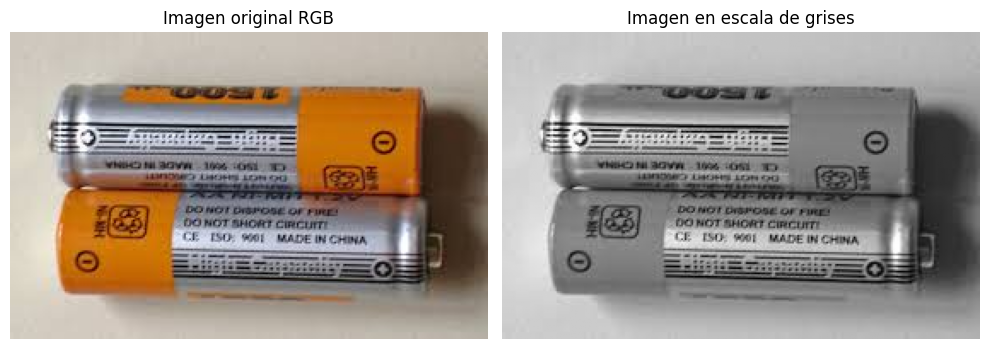

In [5]:
imagen_gris = cv2.cvtColor(
    imagen, cv2.COLOR_BGR2GRAY
)
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(imagen_rgb)
plt.title("Imagen original RGB")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(imagen_gris, cmap="gray")
plt.title("Imagen en escala de grises")
plt.axis("off")

plt.tight_layout()
plt.show()


#HISTOGRAMA

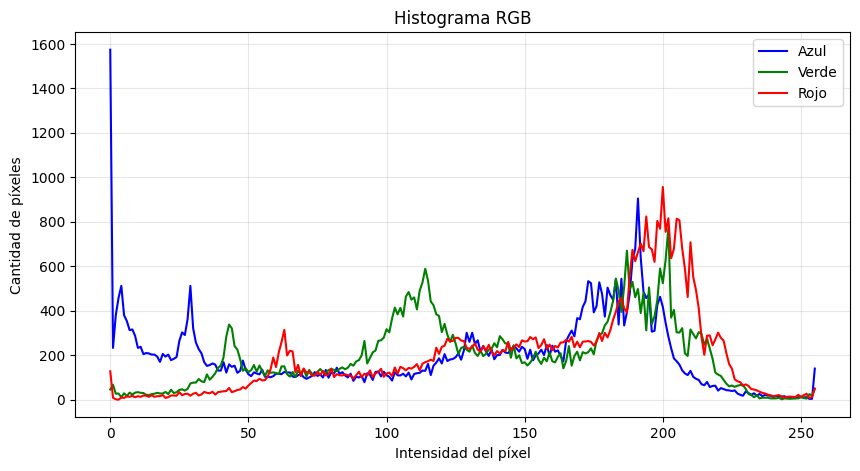

In [6]:
plt.figure(figsize=(10, 5))

colores = ("b", "g", "r")
nombres = ("Azul", "Verde", "Rojo")

for i, color in enumerate(colores):

    histograma = cv2.calcHist(
        [imagen],
        [i],
        None,
        [256],
        [0, 256]
    )

    plt.plot(
        histograma,
        color=color,
        label=nombres[i]
    )

plt.title("Histograma RGB")
plt.xlabel("Intensidad del píxel")
plt.ylabel("Cantidad de píxeles")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


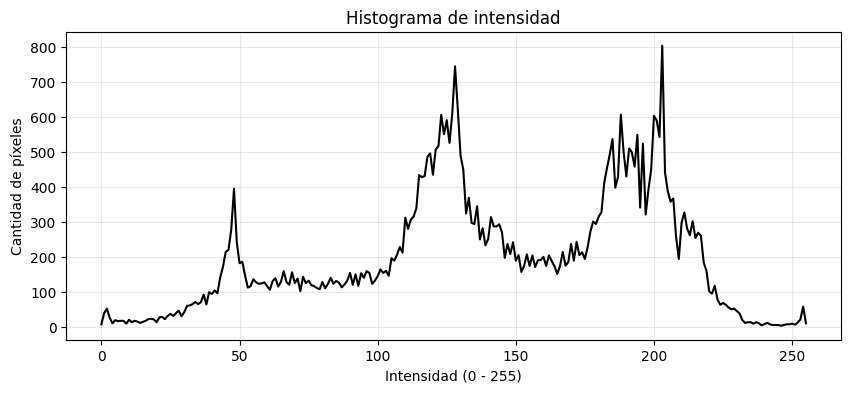

In [7]:
hist_gris = cv2.calcHist(
    [imagen_gris],
    [0],
    None,
    [256],
    [0, 256]
)

plt.figure(figsize=(10, 4))

plt.plot(hist_gris, color="black")
plt.title("Histograma de intensidad")
plt.xlabel("Intensidad (0 - 255)")
plt.ylabel("Cantidad de píxeles")
plt.grid(alpha=0.3)
plt.show()

In [8]:
import os
os.makedirs("/content/resultados", exist_ok=True)
cv2.imwrite(
    "/content/resultados/imagen_grises.png",
    imagen_gris
)
plt.figure(figsize=(10, 5))

for i, color in enumerate(colores):
    hist = cv2.calcHist(
        [imagen], [i], None, [256], [0, 256]
    )
    plt.plot(hist, color=color)

plt.title("Histograma RGB")
plt.xlabel("Intensidad")
plt.ylabel("Cantidad de píxeles")
plt.savefig(
    "/content/resultados/histograma_rgb.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close()

print("Resultados guardados correctamente")


Resultados guardados correctamente


#APLICAR FILTRO PROMEDIO

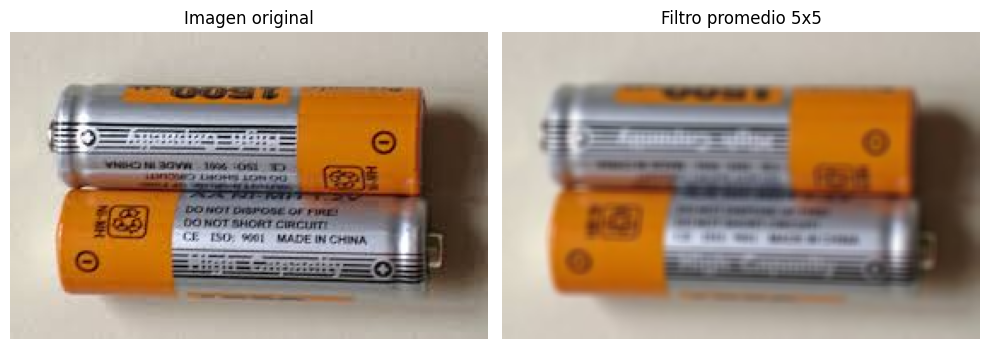

In [9]:
imagen_promedio = cv2.blur(imagen, (5, 5))
promedio_rgb = cv2.cvtColor(
    imagen_promedio,
    cv2.COLOR_BGR2RGB
)
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(imagen_rgb)
plt.title("Imagen original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(promedio_rgb)
plt.title("Filtro promedio 5x5")
plt.axis("off")

plt.tight_layout()
plt.show()


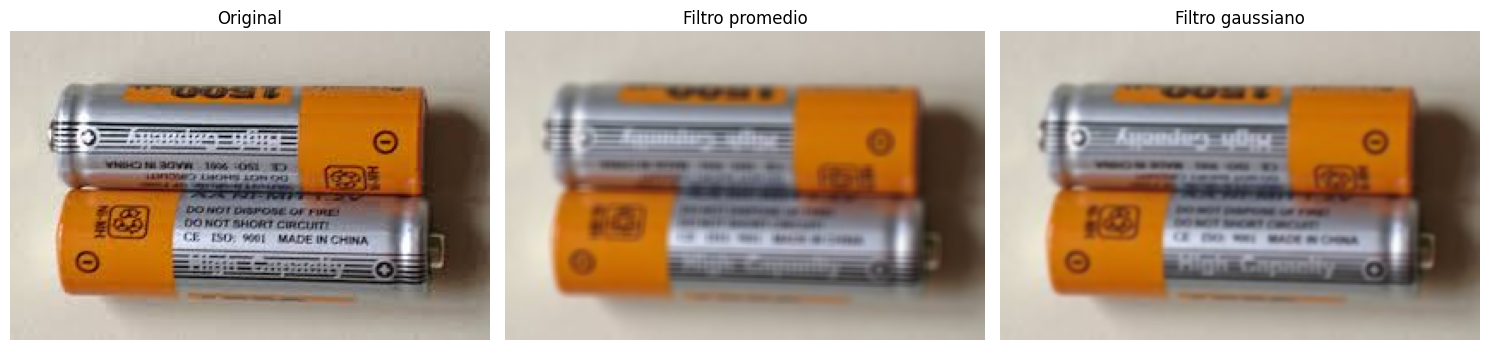

In [10]:
imagen_gaussiana = cv2.GaussianBlur(
    imagen,
    (5, 5),
    sigmaX=0
)
gaussiana_rgb = cv2.cvtColor(
    imagen_gaussiana,
    cv2.COLOR_BGR2RGB
)
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(imagen_rgb)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(promedio_rgb)
plt.title("Filtro promedio")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(gaussiana_rgb)
plt.title("Filtro gaussiano")
plt.axis("off")

plt.tight_layout()
plt.show()


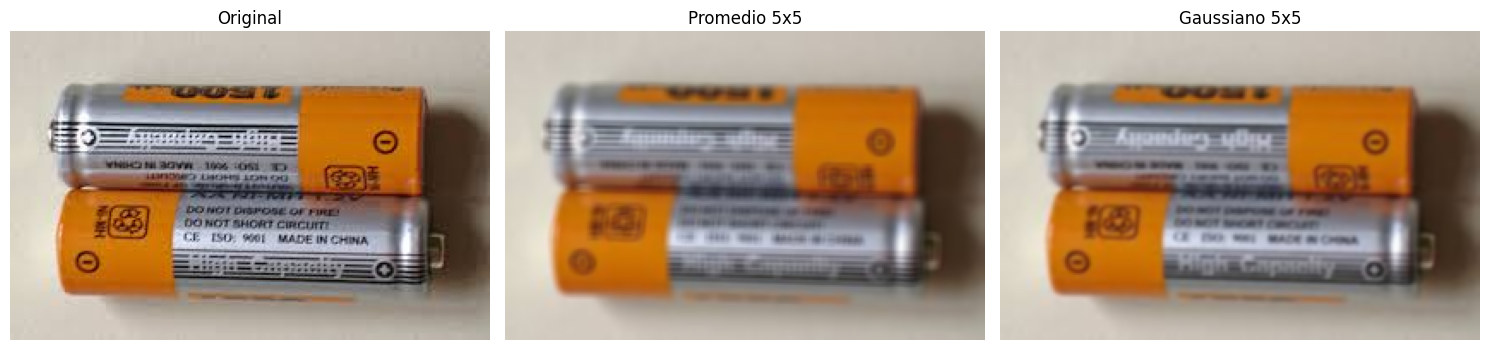

Filtros guardados correctamente


In [11]:
import os
carpeta = "/content/resultados/03_filtros"
os.makedirs(carpeta, exist_ok=True)
cv2.imwrite(
    f"{carpeta}/original.png",
    imagen
)

cv2.imwrite(
    f"{carpeta}/filtro_promedio.png",
    imagen_promedio
)

cv2.imwrite(
    f"{carpeta}/filtro_gaussiano.png",
    imagen_gaussiana
)
plt.figure(figsize=(15, 5))

titulos = ["Original", "Promedio 5x5", "Gaussiano 5x5"]
imagenes = [imagen_rgb, promedio_rgb, gaussiana_rgb]

for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(imagenes[i])
    plt.title(titulos[i])
    plt.axis("off")

plt.tight_layout()

plt.savefig(
    f"{carpeta}/comparacion_filtros.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Filtros guardados correctamente")


#ECUALIZACION

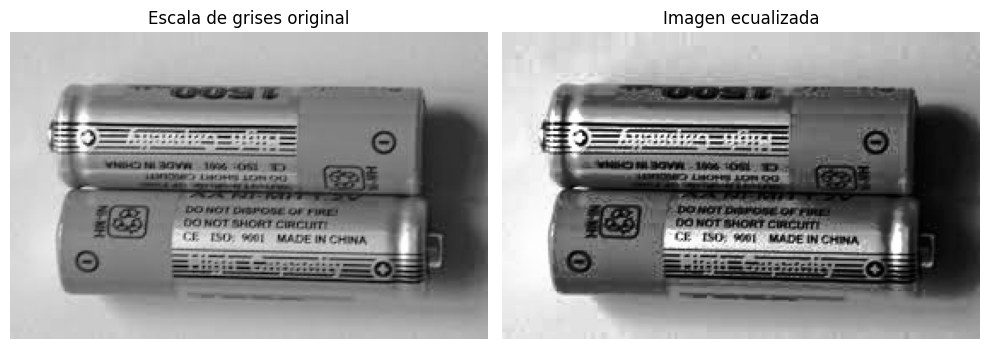

In [12]:
imagen_ecualizada = cv2.equalizeHist(imagen_gris)
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(imagen_gris, cmap="gray")
plt.title("Escala de grises original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(imagen_ecualizada, cmap="gray")
plt.title("Imagen ecualizada")
plt.axis("off")

plt.tight_layout()
plt.show()


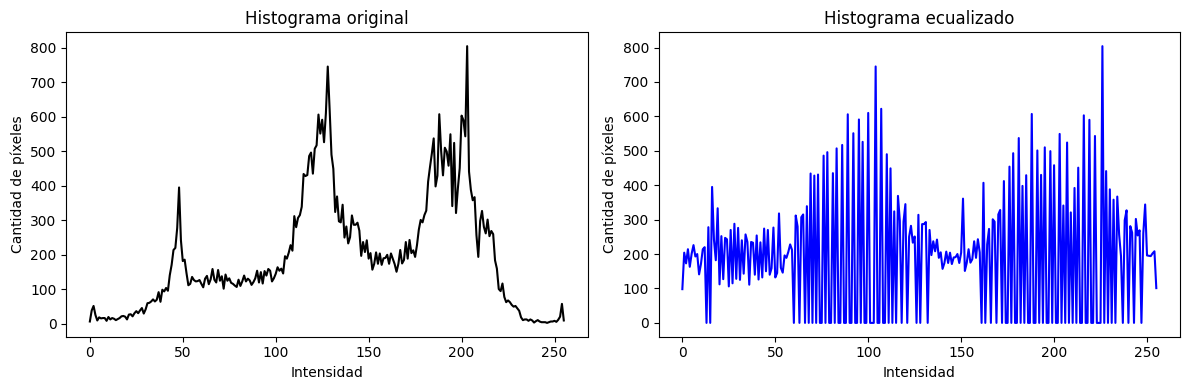

In [13]:
hist_original = cv2.calcHist(
    [imagen_gris], [0], None, [256], [0, 256]
)

hist_ecualizado = cv2.calcHist(
    [imagen_ecualizada], [0], None, [256], [0, 256]
)
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(hist_original, color="black")
plt.title("Histograma original")
plt.xlabel("Intensidad")
plt.ylabel("Cantidad de píxeles")

plt.subplot(1, 2, 2)
plt.plot(hist_ecualizado, color="blue")
plt.title("Histograma ecualizado")
plt.xlabel("Intensidad")
plt.ylabel("Cantidad de píxeles")

plt.tight_layout()
plt.show()


In [14]:
import os

carpeta = "/content/resultados/04_ecualizacion"
os.makedirs(carpeta, exist_ok=True)
cv2.imwrite(
    f"{carpeta}/imagen_ecualizada.png",
    imagen_ecualizada
)
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(hist_original, color="black")
plt.title("Histograma original")

plt.subplot(1, 2, 2)
plt.plot(hist_ecualizado, color="blue")
plt.title("Histograma ecualizado")

plt.tight_layout()

plt.savefig(
    f"{carpeta}/comparacion_histogramas.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()

print("Ecualizacion guardada correctamente")


Ecualizacion guardada correctamente


#UMBRALIZACION

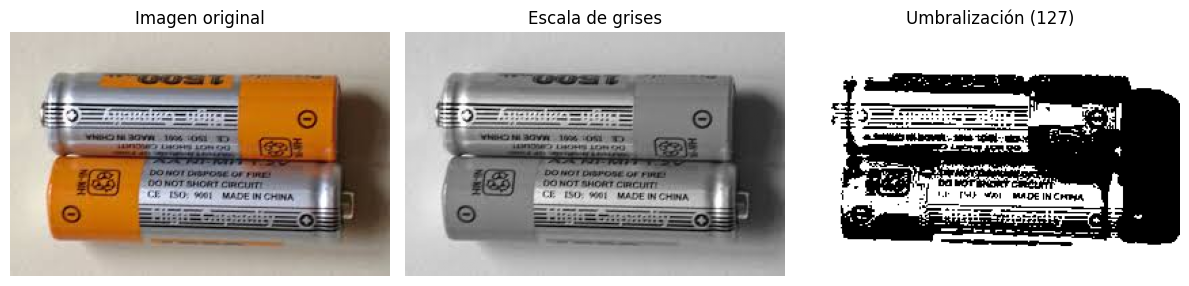

In [15]:
umbral = 127
_, imagen_binaria = cv2.threshold(
    imagen_gris,
    umbral,
    255,
    cv2.THRESH_BINARY
)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(imagen_rgb)
plt.title("Imagen original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(imagen_gris, cmap="gray")
plt.title("Escala de grises")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(imagen_binaria, cmap="gray")
plt.title("Umbralización (127)")
plt.axis("off")

plt.tight_layout()
plt.show()


#UMBRALIZACION AUTOMATICA CON OTSU

Umbral calculado por Otsu: 144.0


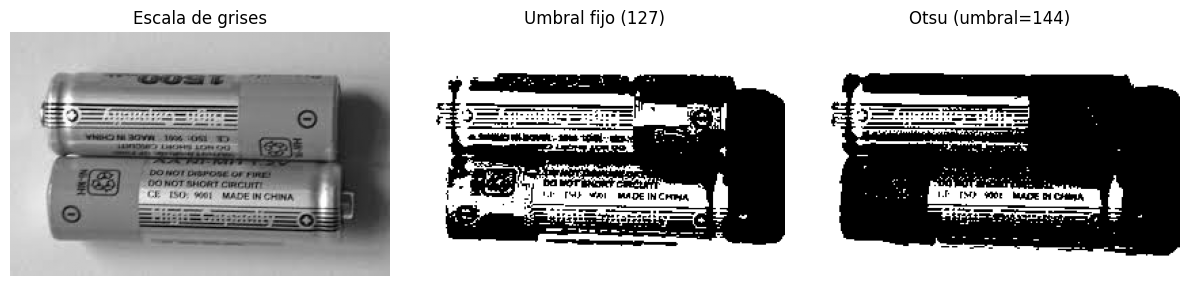

In [16]:
umbral_otsu, imagen_otsu = cv2.threshold(
    imagen_gris,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

print("Umbral calculado por Otsu:", umbral_otsu)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(imagen_gris, cmap="gray")
plt.title("Escala de grises")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(imagen_binaria, cmap="gray")
plt.title("Umbral fijo (127)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(imagen_otsu, cmap="gray")
plt.title(f"Otsu (umbral={umbral_otsu:.0f})")
plt.axis("off")

plt.tight_layout()
plt.show()


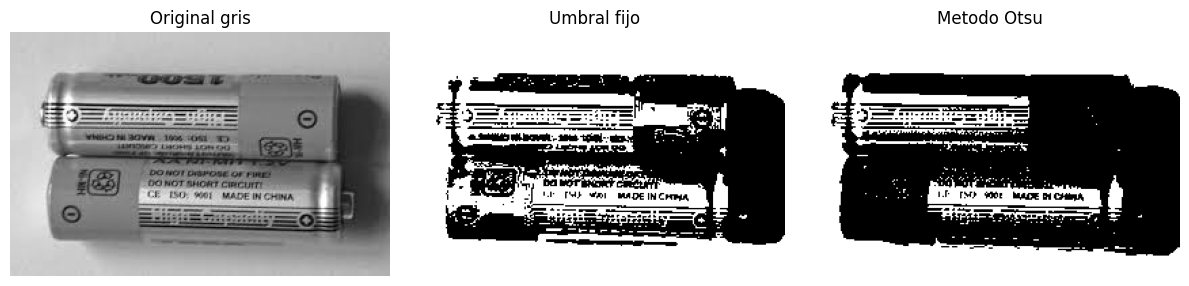

Umbralizaciones guardadas correctamente


In [17]:
import os

carpeta = "/content/resultados/05_umbralizacion"
os.makedirs(carpeta, exist_ok=True)

cv2.imwrite(
    f"{carpeta}/umbral_fijo.png",
    imagen_binaria
)

cv2.imwrite(
    f"{carpeta}/umbral_otsu.png",
    imagen_otsu
)

plt.figure(figsize=(12, 4))

imagenes = [
    imagen_gris,
    imagen_binaria,
    imagen_otsu
]

titulos = [
    "Original gris",
    "Umbral fijo",
    "Metodo Otsu"
]

for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(imagenes[i], cmap="gray")
    plt.title(titulos[i])
    plt.axis("off")

plt.tight_layout()

plt.savefig(
    f"{carpeta}/comparacion_umbralizacion.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Umbralizaciones guardadas correctamente")


##OPERACIONES MORFOLOGICAS

#ELEMENTO ESTRUCTURANTE

In [18]:
kernel = np.ones((3, 3), np.uint8)

print("Elemento estructurante:")
print(kernel)


Elemento estructurante:
[[1 1 1]
 [1 1 1]
 [1 1 1]]


#APLICACION DE OPERACIONES MOROFOLOGICAS

In [19]:
imagen_dilatada = cv2.dilate(
    imagen_otsu,
    kernel,
    iterations=1
)
imagen_erosionada = cv2.erode(
    imagen_otsu,
    kernel,
    iterations=1
)
imagen_apertura = cv2.morphologyEx(
    imagen_otsu,
    cv2.MORPH_OPEN,
    kernel
)
imagen_cierre = cv2.morphologyEx(
    imagen_otsu,
    cv2.MORPH_CLOSE,
    kernel
)

print("Operaciones morfológicas realizadas")

Operaciones morfológicas realizadas


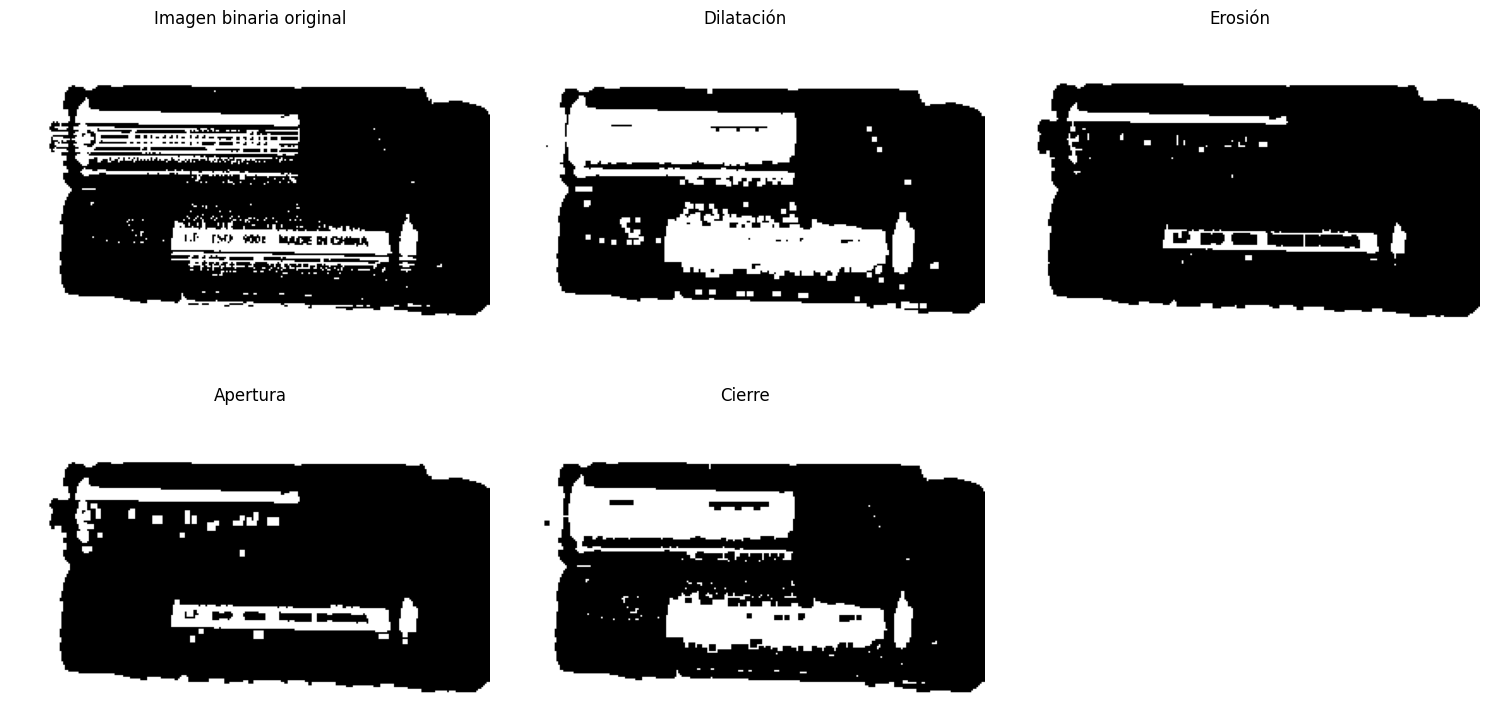

In [20]:
imagenes_morfologia = [
    imagen_otsu,
    imagen_dilatada,
    imagen_erosionada,
    imagen_apertura,
    imagen_cierre
]

titulos = [
    "Imagen binaria original",
    "Dilatación",
    "Erosión",
    "Apertura",
    "Cierre"
]

plt.figure(figsize=(15, 8))

for i in range(5):
    plt.subplot(2, 3, i + 1)

    plt.imshow(
        imagenes_morfologia[i],
        cmap="gray",
        vmin=0,
        vmax=255
    )

    plt.title(titulos[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [21]:
import os
carpeta = "/content/resultados/06_morfologia"
os.makedirs(carpeta, exist_ok=True)

for i in range(5):
    nombre = titulos[i].lower().replace(" ", "_")

    cv2.imwrite(
        f"{carpeta}/{nombre}.png",
        imagenes_morfologia[i]
    )

plt.figure(figsize=(15, 8))

for i in range(5):
    plt.subplot(2, 3, i + 1)
    plt.imshow(
        imagenes_morfologia[i],
        cmap="gray",
        vmin=0,
        vmax=255
    )
    plt.title(titulos[i])
    plt.axis("off")

plt.tight_layout()

plt.savefig(
    f"{carpeta}/comparacion_morfologia.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()

print("Resultados morfológicos guardados")


Resultados morfológicos guardados


#MATRIZ BINARIA

In [23]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

matriz = np.array([
    [0,0,0,0,0,0,0],
    [0,0,0,0,0,0,0],
    [0,0,1,1,1,0,0],
    [0,0,1,1,1,0,0],
    [0,0,1,1,1,0,0],
    [0,0,0,0,0,0,0],
    [0,0,0,0,0,0,0]
], dtype=np.uint8)

kernel = np.ones((3,3), dtype=np.uint8)

print("Matriz original:")
print(matriz)

print("\nElemento estructurante:")
print(kernel)


Matriz original:
[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 1 1 1 0 0]
 [0 0 1 1 1 0 0]
 [0 0 1 1 1 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]

Elemento estructurante:
[[1 1 1]
 [1 1 1]
 [1 1 1]]


In [24]:
matriz_dilatada = cv2.dilate(
    matriz,
    kernel,
    iterations=1,
    borderType=cv2.BORDER_CONSTANT,
    borderValue=0
)

print("Matriz dilatada:")
print(matriz_dilatada)


Matriz dilatada:
[[0 0 0 0 0 0 0]
 [0 1 1 1 1 1 0]
 [0 1 1 1 1 1 0]
 [0 1 1 1 1 1 0]
 [0 1 1 1 1 1 0]
 [0 1 1 1 1 1 0]
 [0 0 0 0 0 0 0]]


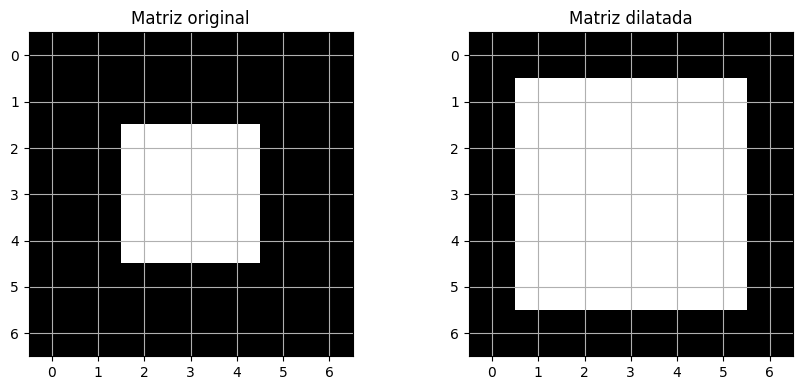

Ejercicio de dilatación guardado


In [25]:
import os

carpeta = "/content/resultados/07_matrices"
os.makedirs(carpeta, exist_ok=True)

plt.figure(figsize=(9, 4))

plt.subplot(1, 2, 1)
plt.imshow(matriz, cmap="gray", vmin=0, vmax=1)
plt.title("Matriz original")
plt.xticks(range(7))
plt.yticks(range(7))
plt.grid()

plt.subplot(1, 2, 2)
plt.imshow(matriz_dilatada, cmap="gray", vmin=0, vmax=1)
plt.title("Matriz dilatada")
plt.xticks(range(7))
plt.yticks(range(7))
plt.grid()

plt.tight_layout()
plt.savefig(
    f"{carpeta}/ejercicio_dilatacion.png",
    dpi=300
)

plt.show()

print("Ejercicio de dilatación guardado")


#erosion

In [26]:
matriz_erosionada = cv2.erode(
    matriz,
    kernel,
    iterations=1,
    borderType=cv2.BORDER_CONSTANT,
    borderValue=0
)

print("Matriz original:")
print(matriz)

print("\nMatriz erosionada:")
print(matriz_erosionada)


Matriz original:
[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 1 1 1 0 0]
 [0 0 1 1 1 0 0]
 [0 0 1 1 1 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]

Matriz erosionada:
[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 1 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]


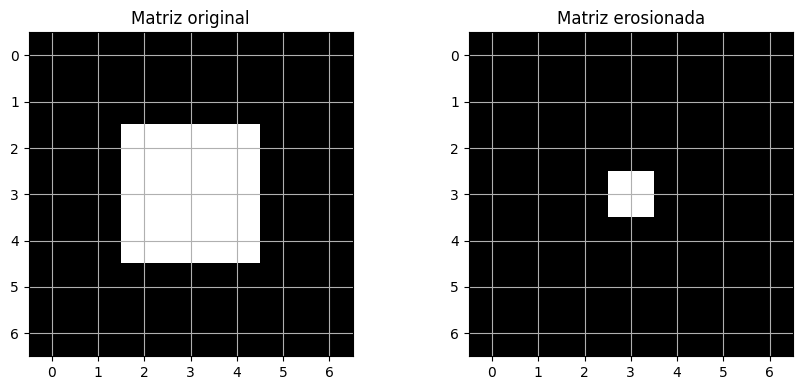

Ejercicio de erosión guardado correctamente


In [27]:
import os

carpeta = "/content/resultados/07_matrices"
os.makedirs(carpeta, exist_ok=True)

plt.figure(figsize=(9, 4))

plt.subplot(1, 2, 1)
plt.imshow(matriz, cmap="gray", vmin=0, vmax=1)
plt.title("Matriz original")
plt.xticks(range(7))
plt.yticks(range(7))
plt.grid()

plt.subplot(1, 2, 2)
plt.imshow(
    matriz_erosionada,
    cmap="gray",
    vmin=0,
    vmax=1
)
plt.title("Matriz erosionada")
plt.xticks(range(7))
plt.yticks(range(7))
plt.grid()

plt.tight_layout()

plt.savefig(
    f"{carpeta}/ejercicio_erosion.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Ejercicio de erosión guardado correctamente")


In [28]:
from pathlib import PurePosixPath
from collections import defaultdict

por_categoria = defaultdict(list)

for ruta in archivos:
    categoria = PurePosixPath(ruta).parent.name
    por_categoria[categoria].append(ruta)

muestra = {}

for categoria in sorted(por_categoria):
    candidatas = sorted(por_categoria[categoria])

    posicion = len(candidatas) // 2

    muestra[categoria] = candidatas[posicion]

print("Categorías seleccionadas:", len(muestra))

for categoria, ruta in muestra.items():
    print(categoria, "->", ruta)


Categorías seleccionadas: 12
battery -> garbage_classification/battery/battery524.jpg
biological -> garbage_classification/biological/biological542.jpg
brown-glass -> garbage_classification/brown-glass/brown-glass372.jpg
cardboard -> garbage_classification/cardboard/cardboard50.jpg
clothes -> garbage_classification/clothes/clothes3395.jpg
green-glass -> garbage_classification/green-glass/green-glass382.jpg
metal -> garbage_classification/metal/metal445.jpg
paper -> garbage_classification/paper/paper526.jpg
plastic -> garbage_classification/plastic/plastic489.jpg
shoes -> garbage_classification/shoes/shoes1889.jpg
trash -> garbage_classification/trash/trash412.jpg
white-glass -> garbage_classification/white-glass/white-glass448.jpg


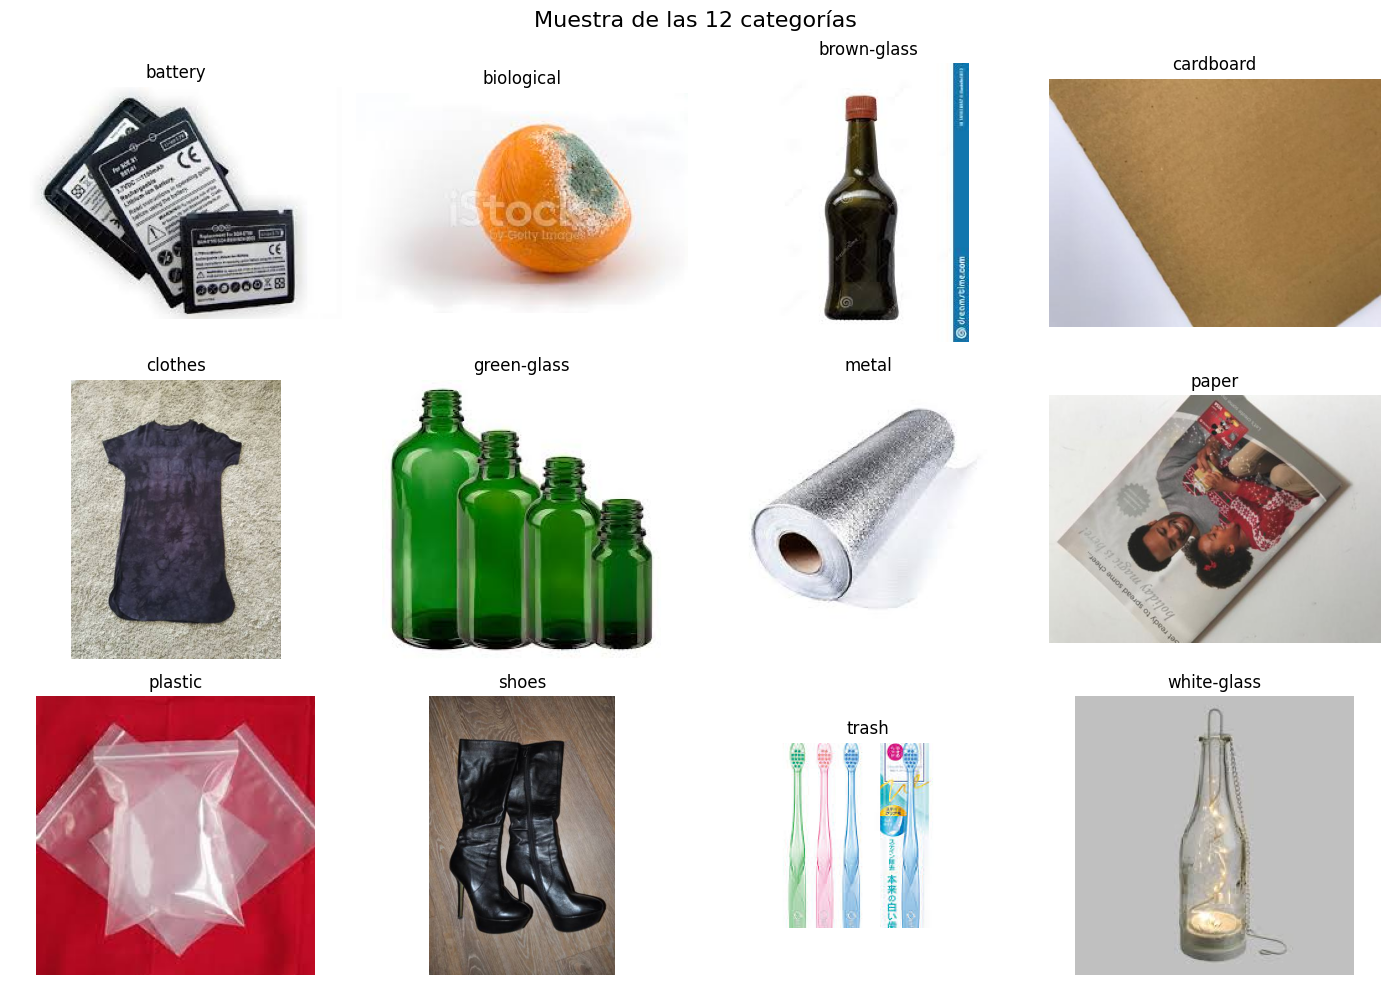

Muestra de 12 categorías guardada


In [29]:
import os
carpeta = "/content/resultados/08_dataset_12_clases"
os.makedirs(carpeta, exist_ok=True)

fig, axes = plt.subplots(3, 4, figsize=(14, 10))

for ax, (categoria, ruta) in zip(
    axes.flat,
    muestra.items()
):
    datos = dataset.read(ruta)

    matriz_img = np.frombuffer(
        datos,
        dtype=np.uint8
    )

    img = cv2.imdecode(
        matriz_img,
        cv2.IMREAD_COLOR
    )

    img_rgb = cv2.cvtColor(
        img,
        cv2.COLOR_BGR2RGB
    )

    ax.imshow(img_rgb)
    ax.set_title(categoria)
    ax.axis("off")

plt.suptitle("Muestra de las 12 categorías", fontsize=16)
plt.tight_layout()

plt.savefig(
    f"{carpeta}/00_muestra_12_categorias.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Muestra de 12 categorías guardada")


In [30]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

base = "/content/resultados/08_dataset_12_clases"

metodos = [
    "01_histogramas",
    "02_filtros",
    "03_ecualizacion",
    "04_umbralizacion",
    "05_morfologia"
]

for metodo in metodos:
    os.makedirs(f"{base}/{metodo}", exist_ok=True)

kernel = np.ones((3, 3), dtype=np.uint8)

for categoria, ruta in muestra.items():

    print("Procesando:", categoria)

    datos = dataset.read(ruta)
    arreglo = np.frombuffer(datos, np.uint8)

    img = cv2.imdecode(
        arreglo, cv2.IMREAD_COLOR
    )

    if img is None:
        print("No se pudo leer:", ruta)
        continue

    alto, ancho = img.shape[:2]

    if max(alto, ancho) > 640:
        escala = 640 / max(alto, ancho)

        img = cv2.resize(
            img,
            None,
            fx=escala,
            fy=escala
        )

    gris = cv2.cvtColor(
        img, cv2.COLOR_BGR2GRAY
    )

    rgb = cv2.cvtColor(
        img, cv2.COLOR_BGR2RGB
    )

    promedio = cv2.blur(img, (5, 5))

    gaussiano = cv2.GaussianBlur(
        img, (5, 5), 0
    )

    ecualizada = cv2.equalizeHist(gris)

    _, binaria = cv2.threshold(
        gris, 127, 255, cv2.THRESH_BINARY
    )

    _, otsu = cv2.threshold(
        gris, 0, 255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    dilatada = cv2.dilate(otsu, kernel)

    erosionada = cv2.erode(otsu, kernel)

    apertura = cv2.morphologyEx(
        otsu, cv2.MORPH_OPEN, kernel
    )

    cierre = cv2.morphologyEx(
        otsu, cv2.MORPH_CLOSE, kernel
    )

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)

    for canal, color in enumerate(["b", "g", "r"]):
        hist = cv2.calcHist(
            [img], [canal], None, [256], [0, 256]
        )
        plt.plot(hist, color=color)

    plt.title("Histograma RGB")
    plt.xlabel("Intensidad")
    plt.ylabel("Píxeles")

    plt.subplot(1, 2, 2)

    hist_gris = cv2.calcHist(
        [gris], [0], None, [256], [0, 256]
    )

    plt.plot(hist_gris, color="black")
    plt.title("Histograma de intensidad")
    plt.xlabel("Intensidad")
    plt.ylabel("Píxeles")

    plt.tight_layout()
    plt.savefig(
        f"{base}/01_histogramas/{categoria}.png",
        dpi=150
    )
    plt.close()

    plt.figure(figsize=(12, 4))

    imagenes = [
        rgb,
        cv2.cvtColor(promedio, cv2.COLOR_BGR2RGB),
        cv2.cvtColor(gaussiano, cv2.COLOR_BGR2RGB)
    ]

    titulos = ["Original", "Promedio", "Gaussiano"]

    for i in range(3):
        plt.subplot(1, 3, i + 1)
        plt.imshow(imagenes[i])
        plt.title(titulos[i])
        plt.axis("off")

    plt.tight_layout()
    plt.savefig(
        f"{base}/02_filtros/{categoria}.png",
        dpi=150
    )
    plt.close()

    plt.figure(figsize=(10, 4))

    for i, imagen_proc in enumerate([gris, ecualizada]):
        plt.subplot(1, 2, i + 1)
        plt.imshow(imagen_proc, cmap="gray",
                   vmin=0, vmax=255)
        plt.title(["Original gris", "Ecualizada"][i])
        plt.axis("off")

    plt.tight_layout()
    plt.savefig(
        f"{base}/03_ecualizacion/{categoria}.png",
        dpi=150
    )
    plt.close()

    plt.figure(figsize=(12, 4))

    imagenes = [gris, binaria, otsu]
    titulos = ["Grises", "Umbral fijo", "Otsu"]

    for i in range(3):
        plt.subplot(1, 3, i + 1)
        plt.imshow(imagenes[i], cmap="gray",
                   vmin=0, vmax=255)
        plt.title(titulos[i])
        plt.axis("off")

    plt.tight_layout()
    plt.savefig(
        f"{base}/04_umbralizacion/{categoria}.png",
        dpi=150
    )
    plt.close()

    imagenes = [
        otsu, dilatada, erosionada,
        apertura, cierre
    ]

    titulos = [
        "Original binaria", "Dilatacion",
        "Erosion", "Apertura", "Cierre"
    ]

    plt.figure(figsize=(12, 7))

    for i in range(5):
        plt.subplot(2, 3, i + 1)
        plt.imshow(imagenes[i], cmap="gray",
                   vmin=0, vmax=255)
        plt.title(titulos[i])
        plt.axis("off")

    plt.tight_layout()
    plt.savefig(
        f"{base}/05_morfologia/{categoria}.png",
        dpi=150
    )
    plt.close()

print("\nProcesamiento automático terminado.")

Procesando: battery
Procesando: biological
Procesando: brown-glass
Procesando: cardboard
Procesando: clothes
Procesando: green-glass
Procesando: metal
Procesando: paper
Procesando: plastic
Procesando: shoes
Procesando: trash
Procesando: white-glass

Procesamiento automático terminado.


In [31]:
total = 0

for metodo in metodos:

    carpeta = f"{base}/{metodo}"

    cantidad = len([
        archivo for archivo in os.listdir(carpeta)
        if archivo.endswith(".png")
    ])

    print(f"{metodo}: {cantidad} imágenes")

    total += cantidad

print("\nTotal de imágenes generadas:", total)


01_histogramas: 12 imágenes
02_filtros: 12 imágenes
03_ecualizacion: 12 imágenes
04_umbralizacion: 12 imágenes
05_morfologia: 12 imágenes

Total de imágenes generadas: 60


Mostrando resultados de: battery

Método: 01_histogramas


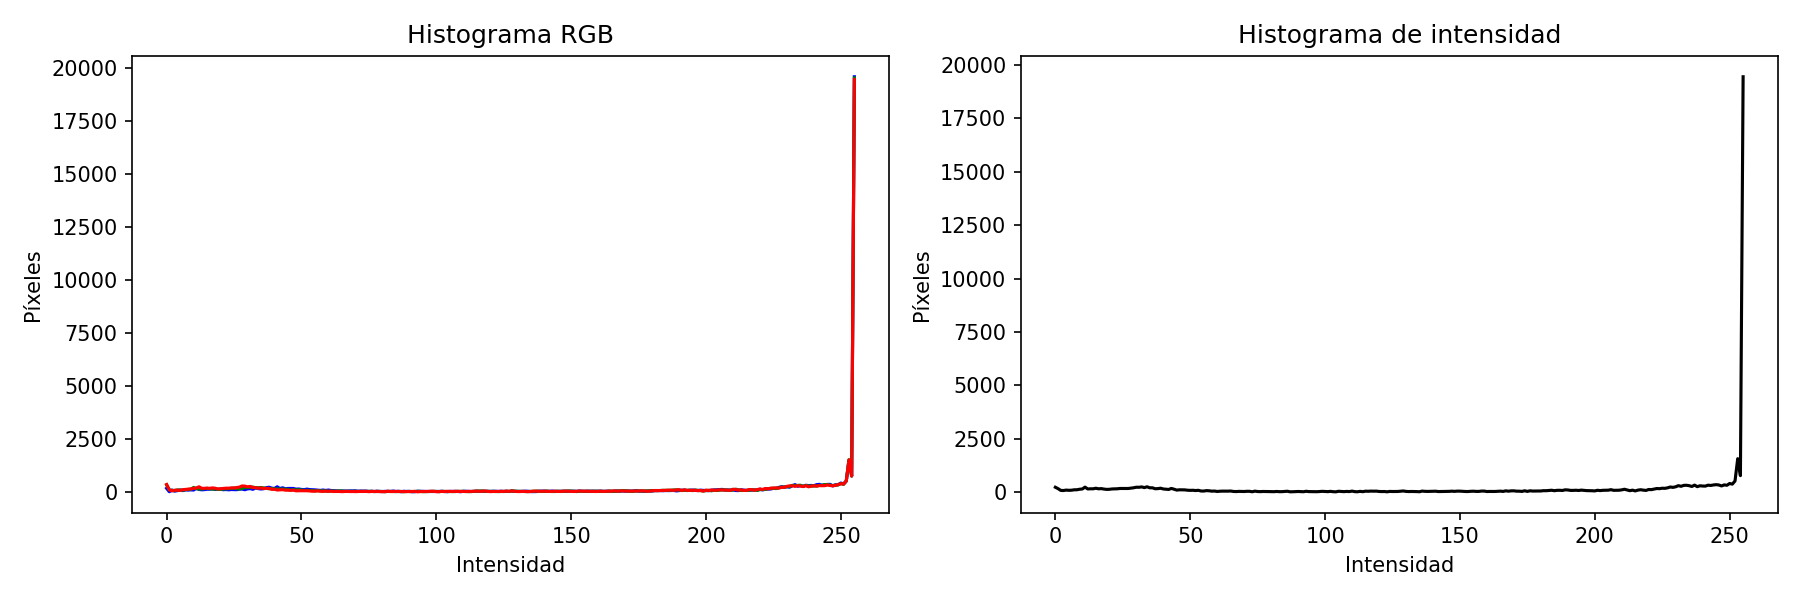


Método: 02_filtros


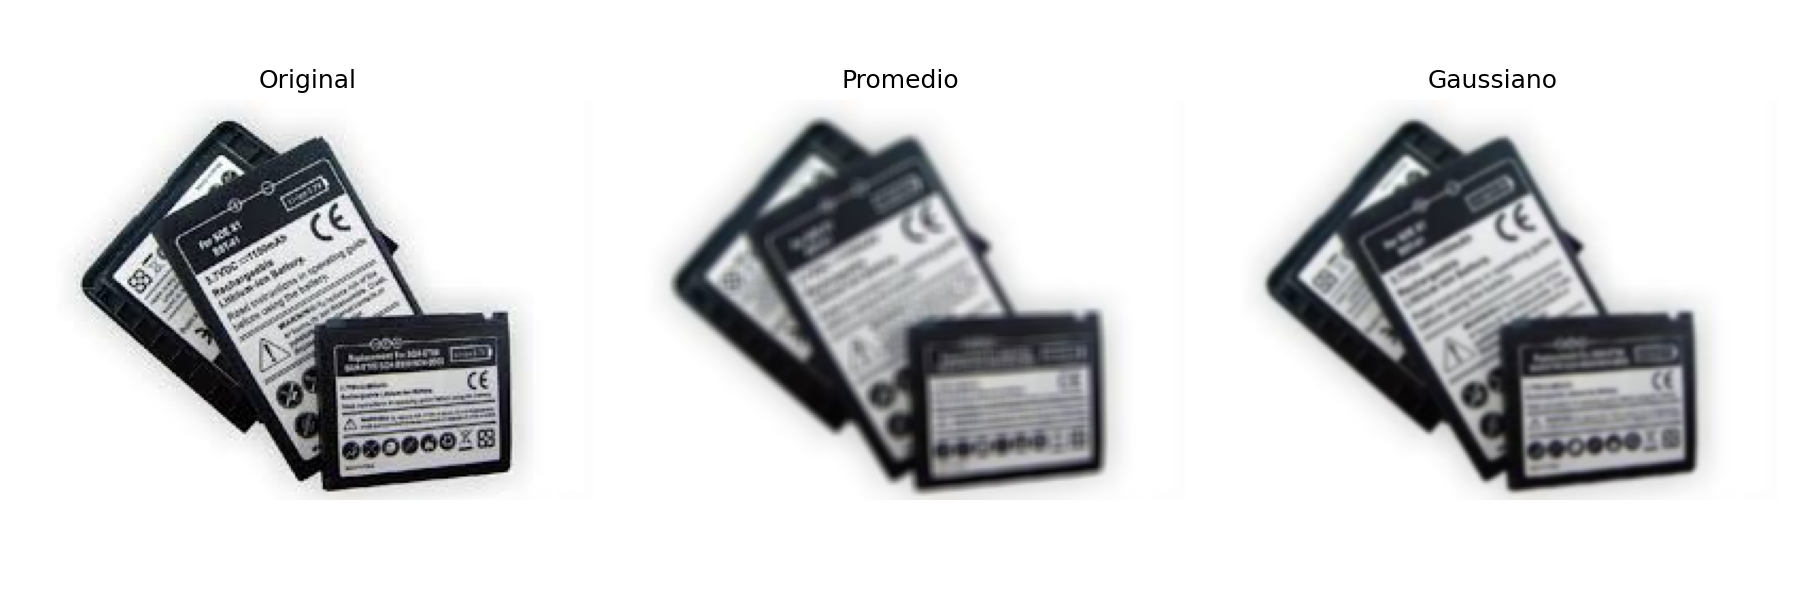


Método: 03_ecualizacion


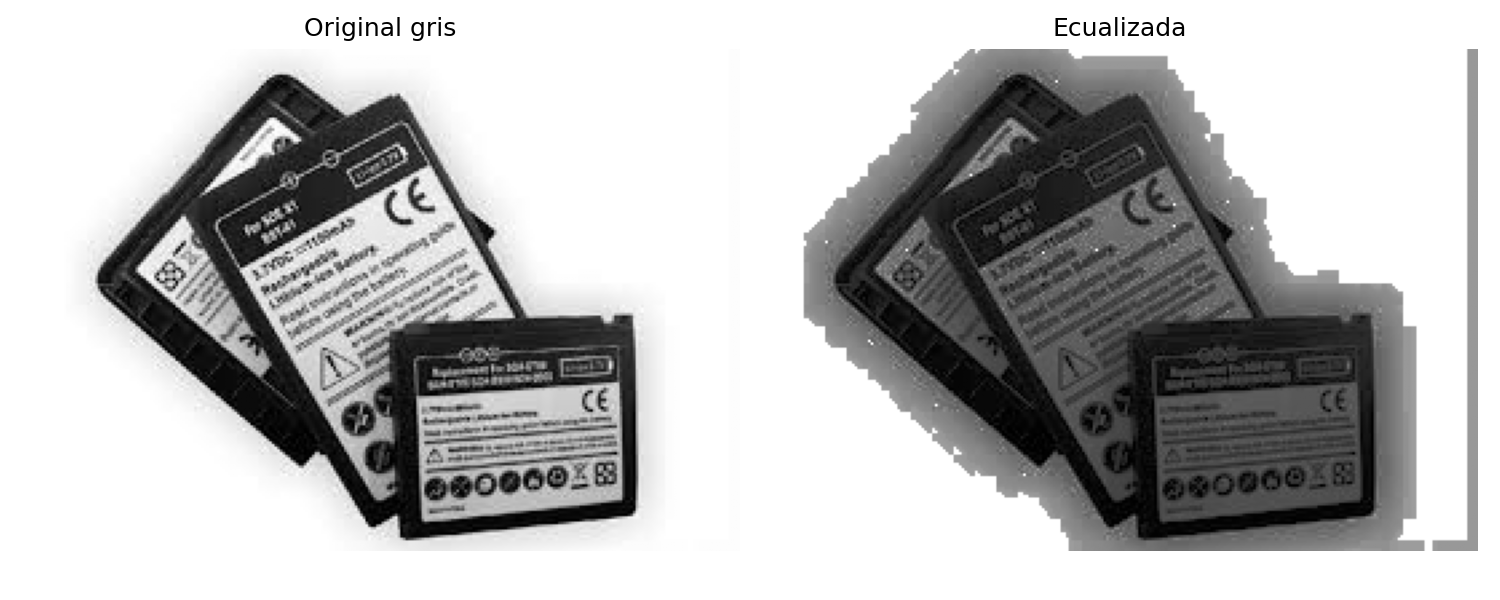


Método: 04_umbralizacion


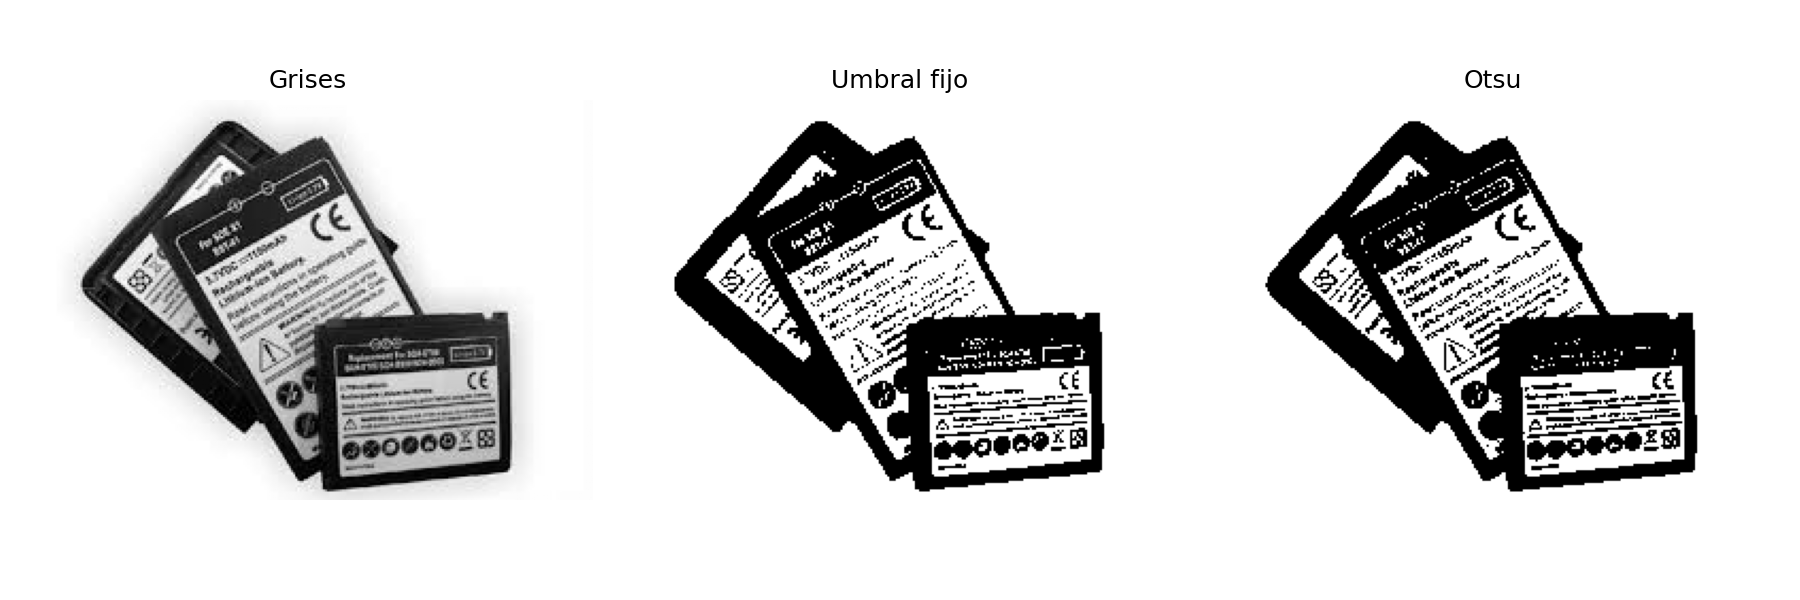


Método: 05_morfologia


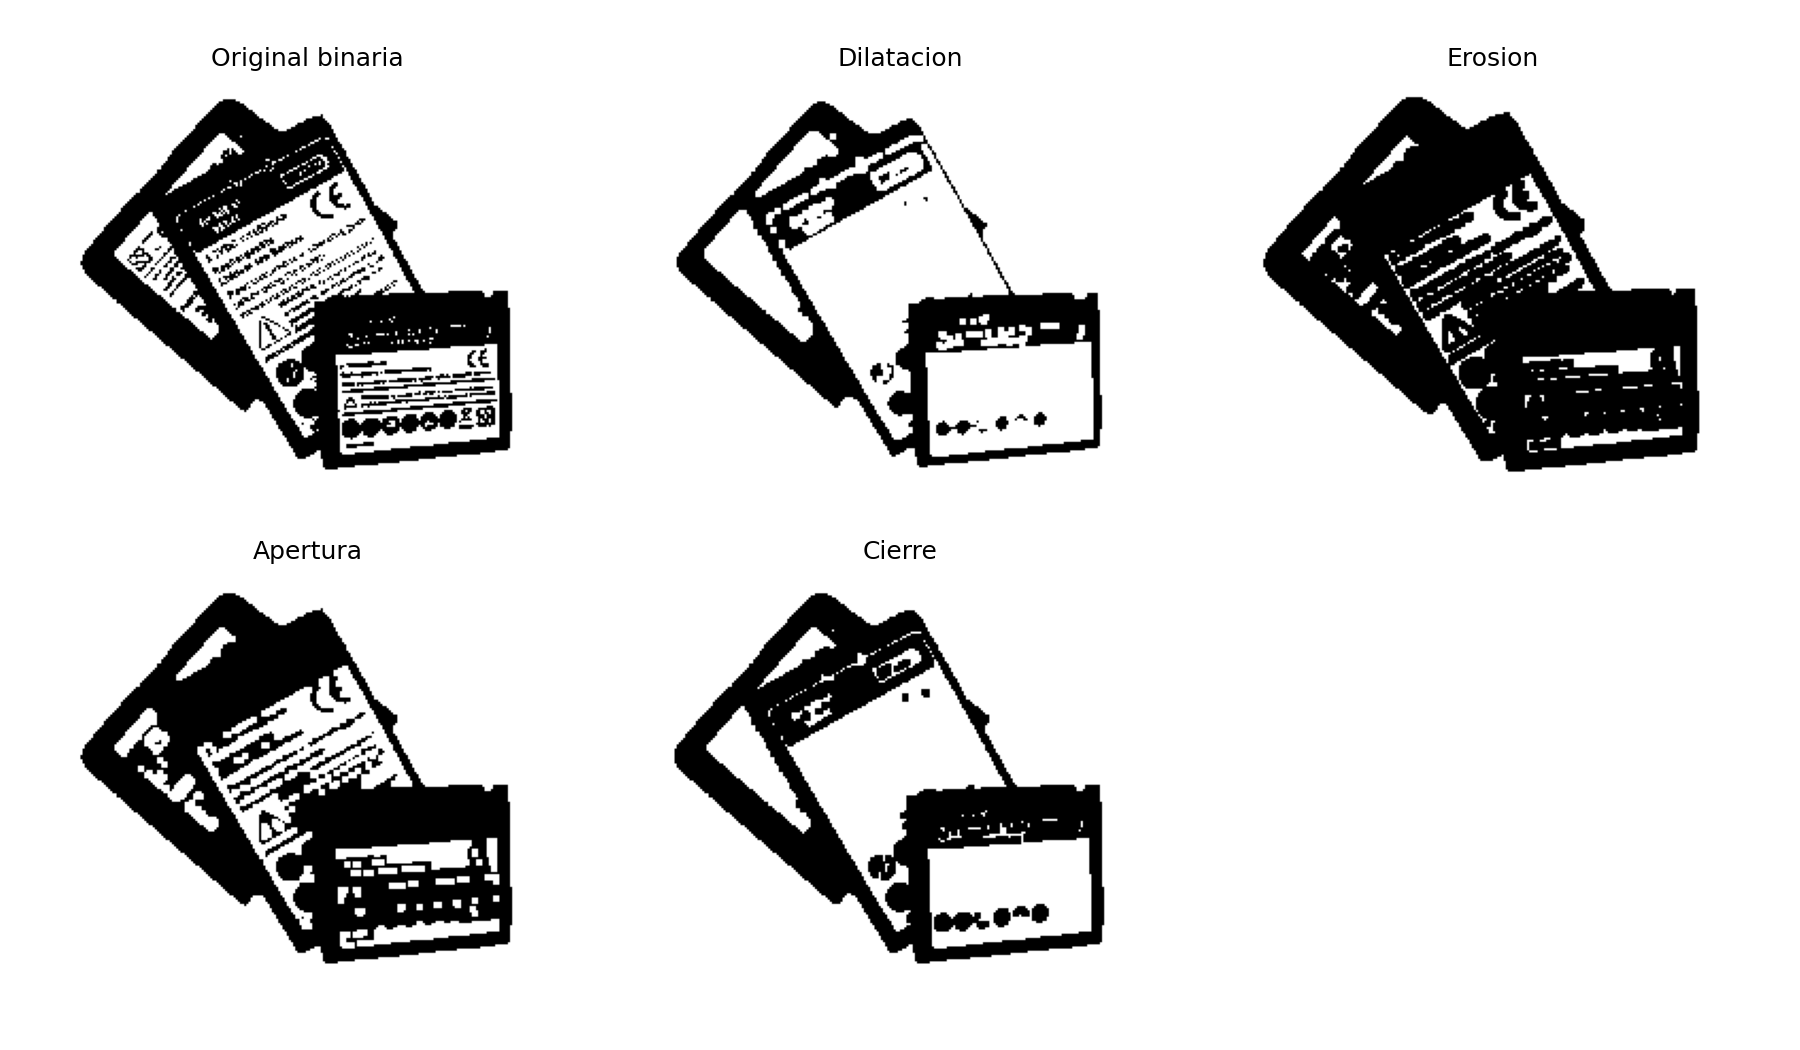

In [32]:
from IPython.display import display, Image
categoria = list(muestra.keys())[0]

print("Mostrando resultados de:", categoria)

for metodo in metodos:

    ruta = f"{base}/{metodo}/{categoria}.png"

    print("\nMétodo:", metodo)

    display(Image(filename=ruta, width=700))


In [33]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

carpeta_pdf = "/content/matrices"
os.makedirs(carpeta_pdf, exist_ok=True)

ruta_pdf = f"{carpeta_pdf}/Adel_Ejercicios_Dilatacion_Erosion.pdf"

def dibujar_matriz(ax, datos, titulo):

    ax.imshow(
        datos,
        cmap="gray",
        vmin=0,
        vmax=1,
        interpolation="nearest"
    )

    ax.set_title(titulo, fontsize=13)

    filas, columnas = datos.shape

    ax.set_xticks(range(columnas))
    ax.set_yticks(range(filas))

    ax.set_xticks(
        np.arange(-0.5, columnas, 1),
        minor=True
    )

    ax.set_yticks(
        np.arange(-0.5, filas, 1),
        minor=True
    )

    ax.grid(
        which="minor",
        color="gray",
        linewidth=0.7
    )

    ax.tick_params(
        which="minor",
        bottom=False,
        left=False
    )

    for i in range(filas):
        for j in range(columnas):

            valor = int(datos[i, j])

            ax.text(
                j, i, str(valor),
                ha="center",
                va="center",
                color="black" if valor == 1 else "white",
                fontsize=10
            )


def agregar_pagina(pdf, resultado, titulo, explicaciones):

    fig, axes = plt.subplots(
        1, 2,
        figsize=(11.7, 8.3)
    )

    fig.suptitle(
        titulo,
        fontsize=17,
        fontweight="bold",
        y=0.93
    )

    dibujar_matriz(
        axes[0],
        matriz,
        "Matriz original"
    )

    dibujar_matriz(
        axes[1],
        resultado,
        "Matriz resultante"
    )

    fig.subplots_adjust(
        top=0.82,
        bottom=0.30,
        wspace=0.25
    )

    fig.text(
        0.07, 0.23,
        "Elemento estructurante: matriz de unos de 3 x 3",
        fontsize=11
    )

    for i, explicacion in enumerate(explicaciones):
        fig.text(
            0.07,
            0.17 - i * 0.045,
            explicacion,
            fontsize=11
        )

    pdf.savefig(fig)
    plt.close(fig)


with PdfPages(ruta_pdf) as pdf:

    agregar_pagina(
        pdf,
        matriz_dilatada,
        "Ejercicio 1: Dilatacion binaria",
        [
            "Paso 1: Se utiliza una matriz binaria de 7 x 7.",
            "Paso 2: Cada ventana de 3 x 3 con al menos un 1 produce un 1.",
            "Resultado: el cuadrado blanco pasa de 3 x 3 a 5 x 5."
        ]
    )

    agregar_pagina(
        pdf,
        matriz_erosionada,
        "Ejercicio 2: Erosion binaria",
        [
            "Paso 1: Se utiliza la misma matriz original.",
            "Paso 2: Una posicion es 1 solo si toda su ventana 3 x 3 es 1.",
            "Resultado: el cuadrado blanco se reduce a un unico pixel."
        ]
    )

print("PDF generado correctamente")
print("Ubicacion:", ruta_pdf)

PDF generado correctamente
Ubicacion: /content/matrices/Adel_Ejercicios_Dilatacion_Erosion.pdf


In [34]:
from google.colab import files
files.download(
    "/content/matrices/Adel_Ejercicios_Dilatacion_Erosion.pdf"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [35]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
import os

os.makedirs("/content/matrices", exist_ok=True)

ruta_pdf = "/content/matrices/Adel_Ejercicios_Dilatacion_Erosion.pdf"

def dibujar(ax, datos, titulo):
    ax.imshow(datos, cmap="gray", vmin=0, vmax=1)
    ax.set_title(titulo, fontsize=13)
    ax.set_xticks(range(7))
    ax.set_yticks(range(7))

    ax.set_xticks(np.arange(-0.5, 7, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, 7, 1), minor=True)
    ax.grid(which="minor", color="gray", linewidth=0.7)
    ax.tick_params(which="minor", length=0)

    for fila in range(7):
        for columna in range(7):
            valor = int(datos[fila, columna])
            ax.text(
                columna, fila, str(valor),
                ha="center", va="center",
                color="black" if valor else "white",
                fontsize=10
            )

with PdfPages(ruta_pdf) as pdf:

    ejercicios = [
        (
            "EJERCICIO 1: DILATACION BINARIA",
            matriz_dilatada,
            [
                "Paso 1: Se parte de una matriz binaria de 7 x 7.",
                "Paso 2: Se utiliza un kernel de 3 x 3 lleno de unos.",
                "Paso 3: Se coloca el kernel sobre cada posicion.",
                "Regla: si existe al menos un 1 en la ventana, el resultado es 1.",
                "Ejemplo (fila 1, columna 1): la ventana contiene un 1 en (2,2).",
                "Por tanto, el valor resultante en (1,1) es 1.",
                "Resultado: el cuadrado de 3 x 3 se expande a 5 x 5."
            ]
        ),
        (
            "EJERCICIO 2: EROSION BINARIA",
            matriz_erosionada,
            [
                "Paso 1: Se utiliza la matriz binaria original de 7 x 7.",
                "Paso 2: Se aplica el mismo kernel de 3 x 3.",
                "Paso 3: Se revisan los nueve valores de cada ventana.",
                "Regla: todos los valores de la ventana deben ser 1.",
                "Ejemplo (fila 3, columna 3): los nueve valores son 1.",
                "Por tanto, el pixel central permanece en 1.",
                "Resultado: el cuadrado se reduce a un unico pixel blanco."
            ]
        )
    ]

    for titulo, resultado, explicaciones in ejercicios:

        fig = plt.figure(figsize=(11.7, 8.3))

        fig.suptitle(
            titulo,
            fontsize=17,
            fontweight="bold",
            y=0.94
        )

        ax1 = fig.add_axes([0.08, 0.43, 0.37, 0.43])
        ax2 = fig.add_axes([0.55, 0.43, 0.37, 0.43])

        dibujar(ax1, matriz, "Matriz original")
        dibujar(ax2, resultado, "Matriz resultante")

        fig.text(
            0.08, 0.37,
            "PROCEDIMIENTO PASO A PASO",
            fontsize=12,
            fontweight="bold"
        )

        for i, linea in enumerate(explicaciones):
            fig.text(
                0.08,
                0.33 - i * 0.041,
                linea,
                fontsize=10.5
            )

        fig.text(
            0.08, 0.025,
            "Nota: las filas y columnas se numeran desde 0.",
            fontsize=9,
            color="gray"
        )

        pdf.savefig(fig)
        plt.close(fig)

print("PDF mejorado generado correctamente")

PDF mejorado generado correctamente


In [36]:
import os
import zipfile
from google.colab import files
nombre_zip = "/content/Adel_Resultados_Matrices.zip"

carpetas = [
    "/content/resultados",
    "/content/matrices"
]

with zipfile.ZipFile(
    nombre_zip,
    "w",
    zipfile.ZIP_DEFLATED
) as zipf:

    for carpeta in carpetas:
        for raiz, dirs, archivos_carpeta in os.walk(carpeta):

            for archivo in archivos_carpeta:

                ruta_completa = os.path.join(
                    raiz, archivo
                )

                # Mantener la estructura de carpetas
                ruta_relativa = os.path.relpath(
                    ruta_completa,
                    "/content"
                )

                zipf.write(
                    ruta_completa,
                    ruta_relativa
                )

print("Archivo ZIP creado correctamente")

files.download(nombre_zip)


Archivo ZIP creado correctamente


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>